<center>

## ARHITEKTURE NEURONSKIH MREŽA
## Vježba 5 <br> **Neuronske mreže za predviđanje kontinuiranih vrijednosti**
<br>



</center>








In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

 Osim za predviđanje diskretnih labela, neuronske mreže se mogu koristiti i za predviđanje kontinuiranih/numeričkih vrijednosti; za **regresijske** probleme.

<h3> KLASIFIKACIJA vs. REGRESIJA </h3>

<br>


<img src="https://www.springboard.com/blog/wp-content/uploads/2021/10/regression-vs.-classification.png" alt="primjer.png" width=600px>



## Skup podataka

U ovim vježbama koristit ćemo **The Boston Housing Price** skup podataka.

> Želimo predvidjeti ***medijalnu cijenu*** nekretnina u danom predgrađu Bostona sredimo 1970-ih godina na temelju podataka o predgrađu koje imamo na raspolaganju poput:
- *stope kriminala*,
- *stope poreza na imovinu*,
- *odnos (omjer) broja učenika i učitelja*
- ...

Više o značajkama koje se uzimaju u obzir prilikom predviđanja možete pronaći na [linku](https://lib.stat.cmu.edu/datasets/boston).

##### Učitavanje podataka

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.boston_housing.load_data()

57026/57026 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
print(f'shape train: {X_train.shape}')
print(f'shape test: {X_test.shape}')

shape train: (404, 13)
shape test: (102, 13)



Na raspolaganju imamo jako malo podataka, ukupno 506 primjera od čega je njih 404 u skupu za treniranja, a preostala 102 primjera su ostavljena za testiranje modela.

In [3]:
X_train[:3]           # prva tri primjera podataka iz skupa za treniranje

array([[1.23247e+00, 0.00000e+00, 8.14000e+00, 0.00000e+00, 5.38000e-01,
        6.14200e+00, 9.17000e+01, 3.97690e+00, 4.00000e+00, 3.07000e+02,
        2.10000e+01, 3.96900e+02, 1.87200e+01],
       [2.17700e-02, 8.25000e+01, 2.03000e+00, 0.00000e+00, 4.15000e-01,
        7.61000e+00, 1.57000e+01, 6.27000e+00, 2.00000e+00, 3.48000e+02,
        1.47000e+01, 3.95380e+02, 3.11000e+00],
       [4.89822e+00, 0.00000e+00, 1.81000e+01, 0.00000e+00, 6.31000e-01,
        4.97000e+00, 1.00000e+02, 1.33250e+00, 2.40000e+01, 6.66000e+02,
        2.02000e+01, 3.75520e+02, 3.26000e+00]])

In [4]:
y_train[:3]           # odgovarajuće labele za te primjere

array([15.2, 42.3, 50. ])

- **labele**: medijalna cijena nekretnina u predgrađu (x 1000\$).

Cijene su obično između 5 000\$ i 50 000\$ (ako izgleda "jeftino", prisjetite se da se radi o cijenama nekretnina sredinom 1970-ih).

Medijalne cijene nekretnina iz skupa za treniranje...
Min: 5.0
Max: 50.0
Medijan: 20.75


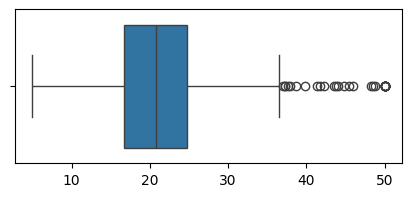

In [11]:
print("Medijalne cijene nekretnina iz skupa za treniranje...")
print("Min:", y_train.min())
print("Max:", y_train.max())
print("Medijan:", np.median(y_train))
plt.figure(figsize=(5,2))
sns.boxplot(x=y_train)
plt.show()

##### Priprema podataka za treniranje mreže

Zbog numeričke stabilnosti i lakšeg/bržeg učenja mreže skaliramo podatke da budu "*na istoj skali*" koristeći *standardizaciju* po značajkama: $$z = \frac{x-\mu}{\sigma}.$$


> "*If the input variables are combined linearly, as in an MLP [Multilayer Perceptron], then it is rarely strictly necessary to standardize the inputs, at least in theory. […] However, there are a variety of practical reasons why standardizing the inputs can make training faster and reduce the chances of getting stuck in local optima.*"
> - [Should I normalize/standardize/rescale the data? Neural Nets FAQ](http://www.faqs.org/faqs/ai-faq/neural-nets/part2/)


In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [13]:
print(scaler.mean_)
print(scaler.scale_)

[3.74511057e+00 1.14801980e+01 1.11044307e+01 6.18811881e-02
 5.57355941e-01 6.26708168e+00 6.90106436e+01 3.74027079e+00
 9.44059406e+00 4.05898515e+02 1.84759901e+01 3.54783168e+02
 1.27408168e+01]
[9.22929073e+00 2.37382770e+01 6.80287253e+00 2.40939633e-01
 1.17147847e-01 7.08908627e-01 2.79060634e+01 2.02770050e+00
 8.68758849e+00 1.66168506e+02 2.19765689e+00 9.39946015e+01
 7.24556085e+00]


**Napomena**: Za standardizaciju podataka iz skupa za testiranje koriste se $\mu$ i $\sigma$ izračunati na **skupu za treniranje**.

In [ ]:
# ### 2. način
# mu = X_train.mean(axis=0)
# std = X_train.std(axis=0)
# X_train -= mu
# X_train /= std
# X_test -= mu
# X_test /= std

In [ ]:
# print(mu)
# print(std)

## Neuronska mreža

##### Arhitektura mreže

In [15]:
def konstruiraj_model():
    model = tf.keras.models.Sequential([
        tf.keras.Input(shape=(X_train.shape[1],)),  # novi ulazni sloj
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(1)  # izlazni sloj bez aktivacije
    ])

    model.compile(loss='mse', optimizer='rmsprop', metrics=['mae'])
    return model

Kada se radi o problemu regresije, neuronska mreža za vrijeme treniranja obično minimizira `mse` (*Mean Squared Error*), odnosno **srednju kvadratnu pogrešku**

$$MSE = \frac{1}{n} \sum\limits_{i=1}^n (y_i - \hat{y_i})^2,$$

pri čemu je
- *n* - broj primjera
- $y_i$ - točna vrijednost izlaza
- $\hat{y}_i$ - predviđena vrijednost.

<br>

U našem primjeru, za vrijeme treniranja također pratimo i vrijednosti `mae` (*Mean Absolute Error*), tj. **srednje apsolutne pogreške**:

$$MAE=\frac{1}{n} \sum\limits_{i=1}^n |y_i - \hat{y_i}|.$$




In [16]:
model = konstruiraj_model()

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 5,121 (20.00 KB)

 Non-trainable params: 0 (0.00 B)

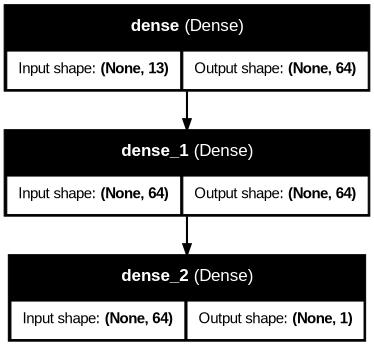

In [21]:
tf.keras.utils.plot_model(
    model,
    show_shapes=True,         # prikazuje dimenzije svakog sloja
    show_layer_names=True,    # prikazuje imena slojeva
    show_dtype=False,         # po želji — možeš staviti True
    dpi=75
)

##### Treniranje

In [22]:
povijest = model.fit(X_train, y_train, verbose=1, epochs=50, batch_size=16)

Epoch 1/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 475.1039 - mae: 19.9702
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 277.3668 - mae: 14.5859
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 132.9380 - mae: 9.1092 
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 68.0754 - mae: 6.2835
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 39.3555 - mae: 4.5811
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 26.0034 - mae: 3.6019
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 21.1576 - mae: 3.1783
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 18.4597 - mae: 2.9611
Epoch 9/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 16.5804 - mae: 2.7831
Epoch 10/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 15.3415 - mae: 2.7109
Epoch 11/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 14.4064 - mae: 2.6369
Epoch 12/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 13.2560 - mae: 2.5621
Epoch 13/50
26/26 ━━━━━━━━━━━━

##### Evaluacija

In [25]:
model.predict(X_test[:5])               # predviđanja mreže trenirane 25 epoha na podacima iz skupa za testiranje

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


array([[ 8.521614],
       [19.229258],
       [22.91494 ],
       [33.252632],
       [26.265486]], dtype=float32)

In [26]:
y_test[:5]                              # točne vrijednosti

array([ 7.2, 18.8, 19. , 27. , 22.2])

In [27]:
test_mse, test_mae = model.evaluate(X_test, y_test, verbose = 0)
print('MSE na skupu za testiranje: {:.4f}'.format(test_mse))
print('MAE na skupu za testiranje: {:.4f}'.format(test_mae))

MSE na skupu za testiranje: 19.7004
MAE na skupu za testiranje: 2.7506


Interpretacija (MAE) <br>
> Primjerice, MAE = 3.2045$\implies$ predviđanja se u prosjeku za 3204.5\$ razlikuju od točnih vrijednosti.

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


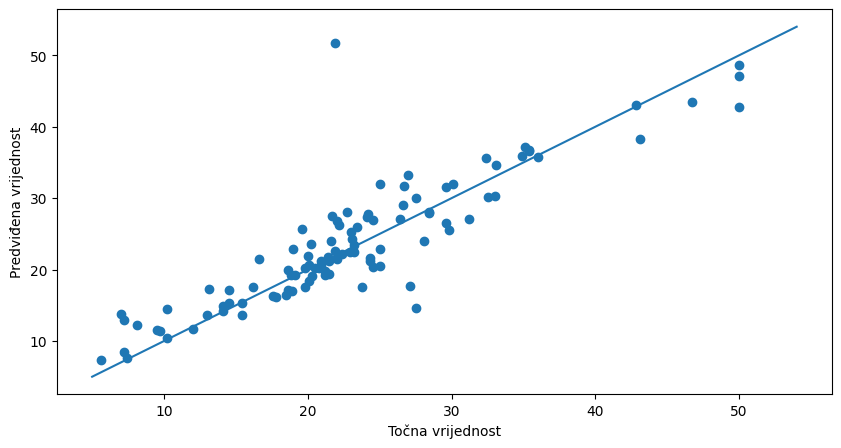

In [28]:
plt.figure(figsize=(10,5))
plt.scatter(y_test, model.predict(X_test))
plt.plot(range(5,55), range(5,55))
plt.xlabel('Točna vrijednost')
plt.ylabel('Predviđena vrijednost')
plt.show()

## Odabir "boljih" vrijednosti hiperparametara

> *Koju veličinu mini-grupe odabrati? Koliko neurona po pojedinom sloju mreže? Koliko  dugo trenirati neuronsku mrežu, koliko epoha?*



Odabrane vrijednosti nekih **hiperparametara** neuronske mreže *(veličina mini grupe tj. batch-size, broja neurona po sloju, broj slojeva mreže, broj epoha koji treniramo mrežu, itd.)* mogu značajno utjecati na konačnu generalizacijsku sposobnost modela, stoga bi željeli odabrati "dobre" vrijednosti za te parametre.

- Za evaluaciju mreže **dok prilagođavamo vrijednosti hiperparametara** (ili dok se ona trenira) koristi se **skup podataka za validaciju**.

**Najčešće se za validaciju "uzme" manji dio podataka iz skupa za treniranje.**






In [29]:
print(X_train.shape[0])
print(round(X_train.shape[0]*0.2))            # kada bi za validaciju "uzeli" 20% podataka iz skupa za treniranje

404
81


Na raspolaganju imamo jako malo podataka pa bi u našem skupu za validaciju bilo cca 100 primjera ili manje.

> **Procjena pogreške neće biti dobra**; rezultati se mogu značajno mijenjati ovisno o tome koje su točke odabrane u skup za validaciju $\implies$ **K-struka unakrsna validacija**.

### K-struka unakrsna validacija (engl. *K-fold Cross-Validation*)

- dijelimo podatke iz skupa za treniranje na *K* "preklopa"
- instanciramo *K* identičnih modela/mreža
- svaki treniramo koristeći *K*-1 preklop za učenje, a preostali 1 za evaluaciju
- rezultat validacije **srednja vrijednost** *K* dobivenih rezultata validacije.





Primjer za *K=5*
<br> <br> <br>
<img alt='cross_validation' src='https://scikit-learn.org/stable/_images/grid_search_cross_validation.png' width='55%'>

In [33]:
from sklearn.model_selection import KFold

In [34]:
k = 5
kf = KFold(n_splits = k)

In [35]:
split_no = 1
for train, val in kf.split(X_train):
    print(f'\nSPLIT {split_no}\n')
    print(f'Train: {train}\n')
    print(f'Val: {val}\n')
    print('-'*100)
    split_no += 1


SPLIT 1

Train: [ 81  82  83  84  85  86  87  88  89  90  91  92  93  94  95  96  97  98
  99 100 101 102 103 104 105 106 107 108 109 110 111 112 113 114 115 116
 117 118 119 120 121 122 123 124 125 126 127 128 129 130 131 132 133 134
 135 136 137 138 139 140 141 142 143 144 145 146 147 148 149 150 151 152
 153 154 155 156 157 158 159 160 161 162 163 164 165 166 167 168 169 170
 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185 186 187 188
 189 190 191 192 193 194 195 196 197 198 199 200 201 202 203 204 205 206
 207 208 209 210 211 212 213 214 215 216 217 218 219 220 221 222 223 224
 225 226 227 228 229 230 231 232 233 234 235 236 237 238 239 240 241 242
 243 244 245 246 247 248 249 250 251 252 253 254 255 256 257 258 259 260
 261 262 263 264 265 266 267 268 269 270 271 272 273 274 275 276 277 278
 279 280 281 282 283 284 285 286 287 288 289 290 291 292 293 294 295 296
 297 298 299 300 301 302 303 304 305 306 307 308 309 310 311 312 313 314
 315 316 317 318 319 320 321 322 3

In [36]:
br_epoha = 50
mae_per_split = []
split_no = 1

for train, val in kf.split(X_train):
  tf.keras.backend.clear_session()
  print(f'\nprocessing SPLIT #{split_no}')

  data_train = X_train[train]
  labels_train = y_train[train]
  data_val = X_train[val]
  labels_val = y_train[val]

  model = konstruiraj_model()
  model.fit(data_train, labels_train,
            epochs=br_epoha,
            batch_size=16,
            verbose=1,
            validation_data=(data_val, labels_val))

  _, val_mae = model.evaluate(data_val, labels_val, verbose=0)
  mae_per_split.append(val_mae)

  split_no += 1


processing SPLIT #1
Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - loss: 562.0942 - mae: 21.9100 - val_loss: 381.5189 - val_mae: 17.7966
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 447.3982 - mae: 19.2135 - val_loss: 277.7978 - val_mae: 14.7297
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 310.8526 - mae: 15.4950 - val_loss: 164.2789 - val_mae: 10.7333
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 176.7676 - mae: 10.9768 - val_loss: 79.1044 - val_mae: 6.6341
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 89.4260 - mae: 7.1766 - val_loss: 45.0404 - val_mae: 4.6066
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 51.5567 - mae: 5.3815 - val_loss: 34.1547 - val_mae: 4.0397
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 35.9267 - mae: 4.4228 - val_loss: 27.8387 - val_mae: 3.4577
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 28.4573 - mae: 3.9391 - val_loss: 23.9009 - val_mae: 3.0204
Epoch 9/50
21/21 ━━

In [ ]:
# 3. ispišite vrijednost MAE za svaki split/MODEL (njih 5)
print('MAE\n' + '-'*20)
for i in range(len(mae_per_split)):
  print('Split {}: {:.4f}'.format(i+1, mae_per_split[i]))

# 4. ispišite aritmetičku sredinu za MAE koju ste dobili pomoću tih 5 različitih modela
print('\nSrednja vrijednost: {:.4f}'.format(np.mean(mae_per_split)))

MAE
--------------------
Split 1: 1.9783
Split 2: 2.9408
Split 3: 2.3881
Split 4: 2.7245
Split 5: 2.7063

Srednja vrijednost: 2.5476


# Zadaci za samostalan rad

> Riješite u bilježnici `ImePrezime_Vj05.ipynb`


### Zadatak 1.

Modificirajte metodu `konstruiraj_model` tako da kao ulazni parametar/parametre prima brojeve neurona koji će se koristiti u **skrivenim** slojevima mreže.

### Zadatak 2.


Koristeći metodu K-struke unakrsne validacije odaberite "najbolju" kombinaciju vrijednosti hiperparametara:
1. broj neurona u skrivenim slojevima mreže
  - usporedite barem dvije proizvoljne arhitekture mreže (npr. ona koja ima 64 neurona u oba skrivena sloja i one koja ima 64 neurona u prvom skrivenom sloju i 32 neurona u drugom skrivenom sloju)
2. veličina mini-grupe tj. `batch_size`
  - usporedite vrijednosti `batch_size` $\in \{8, 16, 32, 64\}$.


> **Napomena:** <br>
> iskoristite modificiranu metodu `konstruiraj_model` iz Zadatka 1.

### Zadatak 3

Trenirajte neuronsku mrežu "otpočetka" (50 epoha) na cijelom originalnom skupu za treniranje s najpovoljnijom kombinacijom hiperparametara iz *Zadatka 2*.

### Zadatak 4

Evaluirajte dobiveni model na skupu za testiranje.
> Usporedite rezultate s onima dobivenim na vježbama s "fiksnom" vrijednosti hiperparametara.
